# 03 · Large Data on Limited RAM

Sooner or later a dataset will not fit comfortably in memory: a laptop has 8 to 16 GB, a small cloud
server 2 to 4 GB, and pandas often needs several times the file size while loading. This module shows how
to measure memory honestly and the techniques, and the alternative libraries, that keep it under control.

**You will learn**
1. How to measure memory: object sizes, and the **peak** memory of a whole process
2. Shrinking a DataFrame: numeric downcasting and categoricals
3. Streaming: process data in chunks or with generators instead of loading everything
4. Columnar files: read only the columns and rows you need
5. Alternatives to pandas: **Polars**, **DuckDB**, **PyArrow** (and when Dask or Spark make sense)
6. A benchmark: the same query six ways, timed and with peak memory measured
7. **PySpark** for data beyond one machine: the same queries with the DataFrame API and with SQL

## 1. Measuring memory
`sys.getsizeof` gives the size of one Python object (not what it contains); `DataFrame.memory_usage(deep=True)`
gives the real size of a table, strings included; `psutil` reports what the whole process uses.

In [1]:
import sys, os, psutil
import numpy as np
import pandas as pd

proc = psutil.Process(os.getpid())
print(f"this kernel uses {proc.memory_info().rss / 1e6:.0f} MB right now")

print(sys.getsizeof(1), "bytes for an int,", sys.getsizeof(1.0), "for a float,", sys.getsizeof("a"), "for a 1-character str")
print(f"a NumPy array of 1M float64: {np.zeros(1_000_000).nbytes / 1e6:.0f} MB; a list of 1M floats: "
      f"~{(sys.getsizeof([0.0] * 1_000_000) + 1_000_000 * sys.getsizeof(0.0)) / 1e6:.0f} MB")

this kernel uses 131 MB right now
28 bytes for an int, 24 for a float, 42 for a 1-character str
a NumPy array of 1M float64: 8 MB; a list of 1M floats: ~32 MB


## 2. Shrinking a DataFrame
pandas defaults to 64-bit numbers and Python strings. Most columns need far less.

In [2]:
rng = np.random.default_rng(0)
n = 1_000_000
df = pd.DataFrame({
    "sensor_id": rng.integers(1, 500, n),                    # fits in int16
    "temperature": rng.normal(21, 4, n),                     # float32 is plenty for a sensor
    "humidity": rng.integers(0, 101, n),                     # fits in uint8
    "status": rng.choice(["ok", "warning", "fault"], n, p=[0.9, 0.08, 0.02]),  # 3 distinct values
    "site": rng.choice([f"site_{i}" for i in range(40)], n),
})

def mb(frame):
    return frame.memory_usage(deep=True).sum() / 1e6

before = mb(df)
small = df.assign(
    sensor_id=pd.to_numeric(df["sensor_id"], downcast="integer"),
    temperature=df["temperature"].astype("float32"),
    humidity=pd.to_numeric(df["humidity"], downcast="unsigned"),
    status=df["status"].astype("category"),
    site=df["site"].astype("category"),
)
print(df.dtypes.to_dict()); print(small.dtypes.to_dict())
print(f"before {before:.0f} MB -> after {mb(small):.0f} MB ({before / mb(small):.1f}x smaller)")

{'sensor_id': dtype('int64'), 'temperature': dtype('float64'), 'humidity': dtype('int64'), 'status': dtype('O'), 'site': dtype('O')}
{'sensor_id': dtype('int16'), 'temperature': dtype('float32'), 'humidity': dtype('uint8'), 'status': CategoricalDtype(categories=['fault', 'ok', 'warning'], ordered=False, categories_dtype=object), 'site': CategoricalDtype(categories=['site_0', 'site_1', 'site_10', 'site_11', 'site_12',
                  'site_13', 'site_14', 'site_15', 'site_16', 'site_17',
                  'site_18', 'site_19', 'site_2', 'site_20', 'site_21',
                  'site_22', 'site_23', 'site_24', 'site_25', 'site_26',
                  'site_27', 'site_28', 'site_29', 'site_3', 'site_30',
                  'site_31', 'site_32', 'site_33', 'site_34', 'site_35',
                  'site_36', 'site_37', 'site_38', 'site_39', 'site_4',
                  'site_5', 'site_6', 'site_7', 'site_8', 'site_9'],
, ordered=False, categories_dtype=object)}
before 131 MB -> after 9 MB (14.

A **category** stores each distinct string once and keeps small integer codes per row. It is the single
biggest win for text columns with few distinct values, and groupby on it is faster too:

In [3]:
import timeit
t_obj = timeit.timeit(lambda: df.groupby("site")["temperature"].mean(), number=5) / 5
t_cat = timeit.timeit(lambda: small.groupby("site", observed=True)["temperature"].mean(), number=5) / 5
print(f"groupby on text: {t_obj * 1000:.0f} ms, on category: {t_cat * 1000:.0f} ms")

groupby on text: 147 ms, on category: 52 ms


## 3. Streaming: chunks and generators
If the result is small (a sum, a count, an average) there is no need to hold all rows at once.

In [4]:
import tempfile
tmp = tempfile.mkdtemp()

# a 3-million-row dataset, written once as CSV and as Parquet, used for the rest of the module
N = 3_000_000
big = pd.DataFrame({
    "sensor_id": rng.integers(1, 500, N).astype("int16"),
    "temperature": rng.normal(21, 4, N).astype("float32"),
    "status": pd.Categorical(rng.choice(["ok", "warning", "fault"], N, p=[0.9, 0.08, 0.02])),
    "site": pd.Categorical(rng.choice([f"site_{i}" for i in range(40)], N)),
    "note": rng.choice(["", "manual check", "recalibrated", "battery low"], N),
})
CSV, PARQUET = os.path.join(tmp, "big.csv"), os.path.join(tmp, "big.parquet")
big.to_csv(CSV, index=False)
big.to_parquet(PARQUET, index=False, row_group_size=250_000)
print(f"CSV {os.path.getsize(CSV) / 1e6:.0f} MB, Parquet {os.path.getsize(PARQUET) / 1e6:.0f} MB")
del big

CSV 104 MB, Parquet 25 MB


In [5]:
# mean temperature of 'fault' readings per site, reading the CSV 250,000 rows at a time
sums, counts = {}, {}
for chunk in pd.read_csv(CSV, chunksize=250_000, usecols=["site", "status", "temperature"]):
    faults = chunk[chunk["status"] == "fault"]
    g = faults.groupby("site")["temperature"]
    for site, s in g.sum().items():
        sums[site] = sums.get(site, 0.0) + s
    for site, c in g.count().items():
        counts[site] = counts.get(site, 0) + c
streamed = pd.Series({k: sums[k] / counts[k] for k in sums}).sort_index()
print(streamed.head())

site_0     21.057986
site_1     21.014257
site_10    20.881563
site_11    20.891889
site_12    21.071960
dtype: float64


In [6]:
# the same idea with a plain generator: a pipeline that never holds the file in memory
def read_lines(path):
    with open(path) as f:
        next(f)                                   # skip the header
        for line in f:
            yield line.rstrip("\n").split(",")

def faults_only(rows):
    return (r for r in rows if r[2] == "fault")   # columns: sensor_id, temperature, status, site, note

count = sum(1 for _ in faults_only(read_lines(CSV)))
print(f"fault rows: {count:,}")

fault rows: 59,835


## 4. Columnar files: read only what you need
Parquet stores each column separately and keeps min/max statistics per block of rows (a *row group*).
A reader can therefore skip columns it does not need (**column pruning**) and whole row groups that
cannot match a filter (**predicate pushdown**).

In [7]:
import pyarrow.parquet as pq
meta = pq.ParquetFile(PARQUET).metadata
print(f"{meta.num_rows:,} rows in {meta.num_row_groups} row groups, {meta.num_columns} columns")

subset = pd.read_parquet(PARQUET, columns=["site", "temperature"], filters=[("status", "==", "fault")])
print(subset.shape, f"{mb(subset):.1f} MB loaded instead of the whole table")

3,000,000 rows in 12 row groups, 5 columns
(59835, 2) 0.3 MB loaded instead of the whole table


## 5. Alternatives to pandas

| Library | What it is | Strengths |
|---|---|---|
| **Polars** | DataFrame library written in Rust, built on Apache Arrow | multi-threaded, lazy queries with an optimiser, streaming for larger-than-RAM data |
| **DuckDB** | an in-process analytical SQL database | SQL directly on Parquet/CSV files, out-of-core execution, very low memory |
| **PyArrow** | the Python library for Apache Arrow, the columnar memory format the others share | zero-copy exchange between tools, datasets, compute functions |
| **Dask** | pandas-like API split into partitions | scales pandas code to many cores or a cluster |
| **Spark (PySpark)** | distributed engine | data that needs a cluster (hundreds of GB and more) |

Rule of thumb: up to a few GB, pandas with good types is fine; beyond that, or when memory is tight,
Polars or DuckDB on Parquet usually solve it on one machine; reach for Dask or Spark only when one
machine is truly not enough.

In [8]:
import polars as pl, duckdb

print(pl.scan_parquet(PARQUET)                 # lazy: nothing is read yet
        .filter(pl.col("status") == "fault")
        .group_by("site").agg(pl.col("temperature").mean())
        .sort("site").head(3).collect())

print(duckdb.sql(f"select site, avg(temperature) as t from '{PARQUET}' where status = 'fault' "
                 "group by site order by site limit 3").df())

shape: (3, 2)
┌─────────┬─────────────┐
│ site    ┆ temperature │
│ ---     ┆ ---         │
│ cat     ┆ f32         │
╞═════════╪═════════════╡
│ site_0  ┆ 21.057985   │
│ site_1  ┆ 21.014257   │
│ site_10 ┆ 20.881563   │
└─────────┴─────────────┘
      site          t
0   site_0  21.057986
1   site_1  21.014257
2  site_10  20.881563


## 6. Benchmark: one query, six ways
Each approach runs in a **fresh Python process** so its peak memory (the operating system's maximum
resident set size) is measured on its own, without anything this notebook already holds. Native
libraries allocate memory outside Python, so this is the only fair way to compare them.

In [9]:
import subprocess, json, textwrap

QUERY = "mean temperature of fault readings per site"
approaches = {
    "pandas read_csv (all columns)": f"""
df = pd.read_csv({CSV!r})
r = df[df.status == 'fault'].groupby('site').temperature.mean()""",
    "pandas read_csv (3 columns, typed)": f"""
df = pd.read_csv({CSV!r}, usecols=['site', 'status', 'temperature'], dtype={{'site': 'category', 'status': 'category', 'temperature': 'float32'}})
r = df[df.status == 'fault'].groupby('site', observed=True).temperature.mean()""",
    "pandas read_csv in chunks": f"""
parts = [c[c.status == 'fault'] for c in pd.read_csv({CSV!r}, usecols=['site', 'status', 'temperature'], chunksize=250_000)]
r = pd.concat(parts).groupby('site').temperature.mean()""",
    "pandas read_parquet (pruned + filtered)": f"""
df = pd.read_parquet({PARQUET!r}, columns=['site', 'temperature'], filters=[('status', '==', 'fault')])
r = df.groupby('site', observed=True).temperature.mean()""",
    "Polars lazy scan": f"""
import polars as pl
r = pl.scan_parquet({PARQUET!r}).filter(pl.col('status') == 'fault').group_by('site').agg(pl.col('temperature').mean()).collect()""",
    "DuckDB SQL": f"""
import duckdb
r = duckdb.sql("select site, avg(temperature) from '{PARQUET}' where status = 'fault' group by site").df()""",
}

def run(snippet):
    # Peak memory = VmHWM ("high water mark") from /proc/self/status, in kB. Unlike getrusage's
    # ru_maxrss it belongs to the new program only: Linux carries ru_maxrss over from the parent
    # (this notebook) through fork and exec, which would hide every difference. (Linux only.)
    prog = ("import time, pandas as pd\nt0 = time.perf_counter()\n" + textwrap.dedent(snippet) +
            "\nhwm = next(l for l in open('/proc/self/status') if l.startswith('VmHWM')).split()[1]"
            "\nprint(time.perf_counter() - t0, hwm)")
    out = subprocess.run([sys.executable, "-c", prog], capture_output=True, text=True, check=True).stdout.split()
    return float(out[-2]), int(out[-1]) / 1024          # seconds, MB

baseline_mb = run("pass")[1]                            # what an empty python + pandas import costs
bench = pd.DataFrame([dict(approach=k, seconds=s, peak_mb=m - baseline_mb) for k, (s, m) in
                      ((k, run(v)) for k, v in approaches.items())]).set_index("approach").round(2)
print(f"{QUERY}; peak memory above a bare 'import pandas' process ({baseline_mb:.0f} MB)")
bench

mean temperature of fault readings per site; peak memory above a bare 'import pandas' process (99 MB)


,seconds,peak_mb
approach,,
pandas read_csv (all columns),4.20,229.27
"pandas read_csv (3 columns, typed)",2.86,37.41
pandas read_csv in chunks,3.44,42.76
pandas read_parquet (pruned + filtered),0.21,108.68
Polars lazy scan,0.91,101.42
DuckDB SQL,0.26,66.62


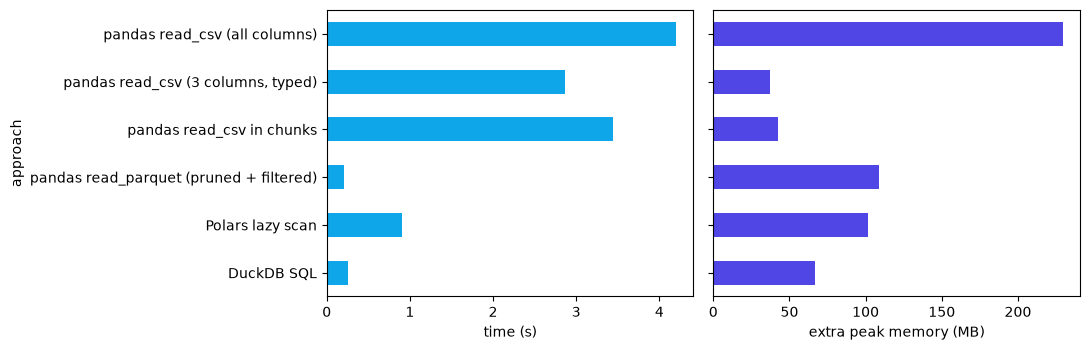

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
bench["seconds"].plot.barh(ax=ax[0], color="#0ea5e9"); ax[0].set_xlabel("time (s)")
bench["peak_mb"].plot.barh(ax=ax[1], color="#4f46e5"); ax[1].set_xlabel("extra peak memory (MB)")
ax[0].invert_yaxis(); plt.tight_layout(); plt.show()

**What the numbers say.** Two different goals, two different winners:
- **Speed** comes from the file format and the engine. Reading a columnar Parquet file with column pruning
  and a filter, or letting DuckDB or Polars run the query, is roughly 6 to 20 times faster than parsing the
  CSV, because nothing irrelevant is ever read or converted from text.
- **Memory** comes from holding less. Loading the whole CSV with default types is by far the most
  memory-hungry option. Asking pandas for only three columns with compact types, or streaming in chunks,
  cuts the peak about five- to six-fold, but parsing text stays slow.
- The extra memory shown for Parquet, Polars and DuckDB is mostly the libraries themselves being loaded
  (the Arrow and DuckDB engines are tens of MB each); at this data size that fixed cost dominates. It stays
  roughly constant as data grows, while a full pandas load grows with the file.

In practice: store data as Parquet, select columns and types up front, and let a query engine (DuckDB or
Polars) do the filtering and aggregation; stream when even the selected data does not fit.

## 7. Beyond one machine: PySpark
When data no longer fits on one machine (hundreds of GB, many TB), or arrives continuously from many
sources, the standard tool is **Apache Spark**, used from Python through **PySpark**. Spark splits a
dataset into **partitions** and processes them in parallel on many **executors** (worker processes, often on
many servers), coordinated by a **driver** (your Python program). Like Polars' lazy mode, nothing runs until
you ask for a result: Spark first builds a plan, and its optimiser (*Catalyst*) rewrites it, pushing filters
and column selection down into the file scan.

| Concept | Meaning |
|---|---|
| `SparkSession` | the entry point; connects to a cluster, or runs everything inside one machine with `local[*]` |
| DataFrame | a distributed table with a schema, split into partitions |
| transformation | `filter`, `select`, `groupBy`, `join`: lazy, only adds to the plan |
| action | `show`, `count`, `collect`, `write`: runs the plan |
| cluster manager | where executors come from: Kubernetes, YARN, Databricks, AWS EMR, Google Dataproc |

The same code runs on a laptop in local mode and on a 100-node cluster; only the session configuration
changes. Spark runs on the Java virtual machine, so it needs a Java runtime (17 or newer).

In [11]:
from pyspark.sql import SparkSession, functions as F, Window

spark = (SparkSession.builder
         .master("local[4]")                                   # 4 worker threads on this machine
         .appName("python1001-large-data")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")         # small data: few partitions after a shuffle
         .config("spark.ui.enabled", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

readings = spark.read.parquet(PARQUET)                          # lazy: only the schema is read
readings.printSchema()
print("partitions:", readings.rdd.getNumPartitions(), "| rows:", f"{readings.count():,}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/18 03:01:06 WARN Utils: Your hostname, patito-HP-Laptop-15-db0xxx, resolves to a loopback address: 127.0.1.1; using 192.168.0.16 instead (on interface wlo1)
26/10/18 03:01:06 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/18 03:01:19 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0


root
 |-- sensor_id: short (nullable = true)
 |-- temperature: float (nullable = true)
 |-- status: string (nullable = true)
 |-- site: string (nullable = true)
 |-- note: string (nullable = true)



partitions: 4 | rows: 3,000,000


### Two ways to write the same query
Spark offers two equivalent interfaces, and teams mix them freely:

1. **The DataFrame API**: method calls on the DataFrame, with column expressions from `pyspark.sql.functions`
   (`F.col`, `F.avg`, `F.when`, ...). Composable, checked by your editor, easy to build programmatically.
2. **SQL**: register the DataFrame as a view and run a query string with `spark.sql("...")`. Familiar to
   anyone who knows SQL, and convenient for long analytical queries.

**Query 1:** mean temperature and count of `fault` readings per site.

In [12]:
# 1) DataFrame API
api_result = (readings
              .filter(F.col("status") == "fault")
              .groupBy("site")
              .agg(F.round(F.avg("temperature"), 3).alias("mean_temp"), F.count("*").alias("n_faults"))
              .orderBy("site"))
api_result.show(5)

+-------+---------+--------+
|   site|mean_temp|n_faults|
+-------+---------+--------+
| site_0|   21.058|    1510|
| site_1|   21.014|    1453|
|site_10|   20.882|    1456|
|site_11|   20.892|    1484|
|site_12|   21.072|    1512|
+-------+---------+--------+
only showing top 5 rows


In [13]:
# 2) SQL: the DataFrame becomes a temporary view that queries can refer to by name
readings.createOrReplaceTempView("readings")
sql_result = spark.sql('''
    SELECT site,
           ROUND(AVG(temperature), 3) AS mean_temp,
           COUNT(*)                   AS n_faults
    FROM readings
    WHERE status = 'fault'
    GROUP BY site
    ORDER BY site
''')
sql_result.show(5)
print("identical results:", api_result.collect() == sql_result.collect())

+-------+---------+--------+
|   site|mean_temp|n_faults|
+-------+---------+--------+
| site_0|   21.058|    1510|
| site_1|   21.014|    1453|
|site_10|   20.882|    1456|
|site_11|   20.892|    1484|
|site_12|   21.072|    1512|
+-------+---------+--------+
only showing top 5 rows


identical results: True


Both are compiled by the same optimiser into the same kind of physical plan, so neither is faster. The plan
shows the optimisation at work: the filter on `status` and the three needed columns are pushed into the
Parquet scan (`PushedFilters`, `ReadSchema`), so the other columns are never read.

In [14]:
api_result.explain()          # the DataFrame API version
sql_result.explain()          # the SQL version: the same operators

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 2
   +- *(3) Sort [site#3 ASC NULLS FIRST], true, 0
      +- AQEShuffleRead coalesced
         +- ShuffleQueryStage 1
            +- Exchange rangepartitioning(site#3 ASC NULLS FIRST, 8), ENSURE_REQUIREMENTS, [plan_id=260]
               +- *(2) HashAggregate(keys=[site#3], functions=[avg(temperature#1), count(1)])
                  +- AQEShuffleRead coalesced
                     +- ShuffleQueryStage 0
                        +- Exchange hashpartitioning(site#3, 8), ENSURE_REQUIREMENTS, [plan_id=228]
                           +- *(1) HashAggregate(keys=[site#3], functions=[partial_avg(temperature#1), partial_count(1)])
                              +- *(1) Project [temperature#1, site#3]
                                 +- *(1) Filter (isnotnull(status#2) AND (status#2 = fault))
                                    +- *(1) ColumnarToRow
                                       +- FileScan parq

**Query 2:** something richer. Per site, the share of readings in each status and the three sensors with the
highest average temperature, using a derived column, a pivot, a join and a **window function**.

In [15]:
# DataFrame API
flagged = readings.withColumn("is_hot", F.when(F.col("temperature") > 28, 1).otherwise(0))
status_share = (flagged.groupBy("site").pivot("status", ["ok", "warning", "fault"]).count()
                .withColumn("total", F.col("ok") + F.col("warning") + F.col("fault"))
                .select("site", *[F.round(F.col(s) / F.col("total") * 100, 2).alias(f"pct_{s}") for s in ["ok", "warning", "fault"]]))
by_sensor = flagged.groupBy("site", "sensor_id").agg(F.avg("temperature").alias("avg_t"), F.sum("is_hot").alias("hot_readings"))
rank_w = Window.partitionBy("site").orderBy(F.col("avg_t").desc())
top3_api = (by_sensor.withColumn("rank", F.row_number().over(rank_w)).filter(F.col("rank") <= 3)
            .join(F.broadcast(status_share), "site")                     # small table: send it to every executor
            .orderBy("site", "rank"))
top3_api.show(6)

+------+---------+------------------+------------+----+------+-----------+---------+
|  site|sensor_id|             avg_t|hot_readings|rank|pct_ok|pct_warning|pct_fault|
+------+---------+------------------+------------+----+------+-----------+---------+
|site_0|      195|22.334422131518384|          14|   1| 89.92|       8.06|     2.02|
|site_0|      191|22.060088488459588|          11|   2| 89.92|       8.06|     2.02|
|site_0|      217|21.775642860226515|           8|   3| 89.92|       8.06|     2.02|
|site_1|      313|   22.034557895806|          12|   1| 90.11|       7.96|     1.94|
|site_1|      228|21.965595207214356|           8|   2| 90.11|       7.96|     1.94|
|site_1|      107|21.913695235925218|          12|   3| 90.11|       7.96|     1.94|
+------+---------+------------------+------------+----+------+-----------+---------+
only showing top 6 rows


In [16]:
# SQL: the same logic, with CTEs, CASE WHEN, conditional aggregation and ROW_NUMBER() OVER (...)
top3_sql = spark.sql('''
    WITH flagged AS (
        SELECT *, CASE WHEN temperature > 28 THEN 1 ELSE 0 END AS is_hot FROM readings
    ),
    status_share AS (
        SELECT site,
               ROUND(100 * AVG(CASE WHEN status = 'ok'      THEN 1 ELSE 0 END), 2) AS pct_ok,
               ROUND(100 * AVG(CASE WHEN status = 'warning' THEN 1 ELSE 0 END), 2) AS pct_warning,
               ROUND(100 * AVG(CASE WHEN status = 'fault'   THEN 1 ELSE 0 END), 2) AS pct_fault
        FROM flagged GROUP BY site
    ),
    ranked AS (
        SELECT site, sensor_id, AVG(temperature) AS avg_t, SUM(is_hot) AS hot_readings,
               ROW_NUMBER() OVER (PARTITION BY site ORDER BY AVG(temperature) DESC) AS rank
        FROM flagged GROUP BY site, sensor_id
    )
    SELECT r.*, s.pct_ok, s.pct_warning, s.pct_fault
    FROM ranked r JOIN status_share s USING (site)
    WHERE rank <= 3
    ORDER BY site, rank
''')
top3_sql.show(6)
cols = ["site", "sensor_id", "rank", "pct_fault"]
print("same rows:", top3_api.select(cols).collect() == top3_sql.select(cols).collect())

+------+---------+------------------+------------+----+------+-----------+---------+
|  site|sensor_id|             avg_t|hot_readings|rank|pct_ok|pct_warning|pct_fault|
+------+---------+------------------+------------+----+------+-----------+---------+
|site_0|      195|22.334422131518384|          14|   1| 89.92|       8.06|     2.02|
|site_0|      191|22.060088488459588|          11|   2| 89.92|       8.06|     2.02|
|site_0|      217|21.775642860226515|           8|   3| 89.92|       8.06|     2.02|
|site_1|      313|   22.034557895806|          12|   1| 90.11|       7.96|     1.94|
|site_1|      228|21.965595207214356|           8|   2| 90.11|       7.96|     1.94|
|site_1|      107|21.913695235925218|          12|   3| 90.11|       7.96|     1.94|
+------+---------+------------------+------------+----+------+-----------+---------+
only showing top 6 rows


same rows: True


### Getting results out, and writing data
`toPandas()` brings a result to the driver as a pandas DataFrame: do it only with **small** results, never
with the raw data. Large outputs are written back to storage, usually Parquet partitioned by a column so
later queries can skip whole folders.

In [17]:
small = top3_sql.toPandas()                       # fine: a few hundred rows
print(type(small).__name__, small.shape)

out = os.path.join(tmp, "spark_out")
(readings.filter(F.col("status") != "ok")
         .write.mode("overwrite").partitionBy("status").parquet(out))
print(sorted(d for d in os.listdir(out) if not d.startswith(("_", "."))))
# SQL can also query files directly, without registering a view first
spark.sql(f"SELECT status, COUNT(*) AS n FROM parquet.`{out}` GROUP BY status ORDER BY status").show()

DataFrame (120, 8)


['status=fault', 'status=warning']


+-------+------+
| status|     n|
+-------+------+
|  fault| 59835|
|warning|240089|
+-------+------+



### Is Spark faster here?

In [18]:
import time
t0 = time.perf_counter(); api_result.collect(); t_spark = time.perf_counter() - t0
t0 = time.perf_counter()
duckdb.sql(f"select site, avg(temperature), count(*) from '{PARQUET}' where status = 'fault' group by site").df()
t_duck = time.perf_counter() - t0
print(f"query 1 with both engines already running: Spark {t_spark:.2f} s, DuckDB {t_duck:.2f} s")
spark.stop()

query 1 with both engines already running: Spark 0.19 s, DuckDB 0.13 s


On one machine and a few million rows, no: Spark plans the query, schedules tasks and moves data between
them in a separate Java process, overheads that single-node engines like DuckDB and Polars avoid. Spark pays
off when the data or the work is too large for one machine, when the data already lives in a data lake or
warehouse that Spark reads natively, or for streaming pipelines. A sensible path: pandas, then Polars or
DuckDB, then Spark.

| Tool | Function-style API | SQL style |
|---|---|---|
| **PySpark** | `df.filter(F.col("x") > 1).groupBy("k").agg(F.avg("v"))` | `df.createOrReplaceTempView("t")`, then `spark.sql("SELECT k, AVG(v) FROM t WHERE x > 1 GROUP BY k")` |
| **Polars** | `df.filter(pl.col("x") > 1).group_by("k").agg(pl.col("v").mean())` | `df.sql("SELECT k, AVG(v) FROM self WHERE x > 1 GROUP BY k")` |
| **DuckDB** | relational API: `duckdb.table("t").filter("x > 1").aggregate("k, avg(v)")` | `duckdb.sql("SELECT ...")`, which can also query pandas DataFrames by name |
| **pandas** | `df[df.x > 1].groupby("k")["v"].mean()` | `df.query("x > 1")` takes a filter expression, not full SQL |

Spark also offers a pandas-like API (`import pyspark.pandas as ps`) for teams moving pandas code to a cluster.

## Checklist for memory-constrained processing
1. **Measure first**: `memory_usage(deep=True)`, `psutil`, or the peak of a test run.
2. **Store as Parquet**, not CSV, and read only the needed columns and rows.
3. **Use the right types**: `category` for repeated strings, `float32`/small integers where precision allows.
4. **Stream** when the result is small: chunks, generators, or a lazy engine.
5. **Delete what you no longer need** (`del df`) and avoid accidental copies.
6. **Let a query engine do the work** (DuckDB, Polars) when pandas would load everything.
7. Only then think about more RAM or a cluster (Spark, section 7).

## Exercises
1. Repeat the benchmark with `sensor_id` as the group key. Does the ranking change?
2. Add an approach using `pyarrow.dataset` with a filter expression and compare it.
3. Use `pl.scan_csv` instead of `scan_parquet`: how much of Polars' advantage comes from the file format?
4. In PySpark, find the hottest single reading per site twice: with `Window` and `F.max`, and in SQL with `MAX(...) OVER (PARTITION BY site)`. Check both give the same rows.